# Descriptive stats for all columns

In [9]:
import matplotlib as plt
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Load the Data

In [4]:
RAW = "../data/data/raw"
df = pd.read_csv(f"{RAW}/diabetic_data.csv")
variables = pd.read_csv(f"{RAW}/variables.csv")

df.shape


C:\Users\piedu\AppData\Local\Temp\ipykernel_14268\810355052.py:2: DtypeWarning: Columns (8: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{RAW}/diabetic_data.csv")


(101766, 48)

#### View of Numerical data

In [ ]:
df.describe()

,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


#### View of Categorical data

In [ ]:
for col in df.select_dtypes("object"):
    print(df[col].value_counts(dropna=False))

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64
weight
NaN          98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64
payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64
medical

C:\Users\piedu\AppData\Local\Temp\ipykernel_14268\2129828507.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


Number of Categorical vs Numerical Columns

In [7]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

print(f"Numeric columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Total: {df.shape[1]}")

Numeric columns: 11
Categorical columns: 37
Total: 48


## Three-Class Readmitted Split

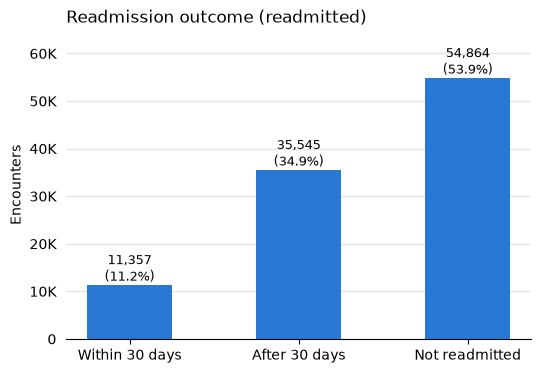

In [10]:
# Count each class in a meaningful order (not sorted by size)
order = ["<30", ">30", "NO"]
counts = df["readmitted"].value_counts().reindex(order)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Within 30 days", "After 30 days", "Not readmitted"], counts,
              width=0.5, color="#2a78d6")

# Count + percentage on top of each bar
for bar, n, p in zip(bars, counts, pct):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=9)

ax.set_title("Readmission outcome (readmitted)", loc="left")
ax.set_ylabel("Encounters")
ax.yaxis.set_major_formatter(lambda y, _: f"{y/1000:.0f}K" if y else "0")
ax.set_ylim(0, counts.max() * 1.18)        # headroom for the labels
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)                     # gridlines behind bars
ax.tick_params(left=False)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

out = Path("../reports/figures")
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "readmitted_split.png", dpi=200, bbox_inches="tight")
plt.show()
